In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.widgets as mwidgets
import matplotlib.path as mpath
import numpy as np
import matplotlib.path as mpath
from cartopy.io.img_tiles import GoogleWTS

class EsriShadedRelief(GoogleWTS):
    def _image_url(self, tile):
        x_tile, y_tile, zoom = tile
        return (
            "https://server.arcgisonline.com/ArcGIS/rest/services/"
            f"World_Shaded_Relief/MapServer/tile/{zoom}/{y_tile}/{x_tile}"
        )

topo_tiles = EsriShadedRelief(cache=True)

In [11]:
%matplotlib widget

## load data from repo root

In [12]:
# Load data
from pathlib import Path

current = Path.cwd().resolve()
repo_root = next(
    folder for folder in (current, *current.parents)
    if (folder / ".git").exists()
)
file_path = repo_root / "archy494data_burialcoords(1).xlsx"
#df = pd.read_excel(file_path)

In [13]:
# Confirm sheet_name=3 is "allburials"
workbook = pd.ExcelFile(file_path)
print(workbook.sheet_names)

allburials_raw = pd.read_excel(file_path, sheet_name=3)

# Normalize column names for easier access
allburials_raw.columns = (
    allburials_raw.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("-", "_")
)

['dataage', 'datatype', 'burialtables', 'allburials', 'burialcoords']


## cleaning and refactoring allburials as binary columns

In [14]:
# Normalize category values for consistent matching; leave missing values missing.
age = allburials_raw["age_category"].astype("string").str.strip().str.lower()
location = allburials_raw["location"].astype("string").str.strip().str.lower()
burial_type = allburials_raw["type"].astype("string").str.strip().str.lower()

burials_df = pd.DataFrame({
    "site": allburials_raw["site"],
    "subadult": age.isin(["infant", "subadult"]).astype(int),
    "adult": age.eq("adult").astype(int),
    "intramural": location.eq("intramural").astype(int),
    "extramural": location.eq("extramural").astype(int),
    "pithoi": burial_type.eq("pithoi").astype(int),
    "simple_internment": burial_type.isin(
        ["simple internment", "simple interment"]
    ).astype(int),
    "refuse_pit": burial_type.eq("refuse pit").astype(int),
    #"unknown": burial_type.eq("unknown").astype(int), #HOW DO I COUNT UNKOWN AS ZERO IN TYPES
    "other_type": (
        burial_type.notna()
        & burial_type.ne("unknown")
        & ~burial_type.isin([
            "pithoi",
            "simple internment",
            "simple interment",
            "refuse pit",
        ])
    ).astype(int),
})

display(burials_df.head())
print(burials_df.sum(numeric_only=True))

,site,subadult,adult,intramural,extramural,pithoi,simple_internment,refuse_pit,other_type
0,Kalınkaya-Toptaştepe,1,0,0,0,0,0,0,0
1,Kalınkaya-Toptaştepe,1,0,0,0,0,0,0,0
2,Kalınkaya-Toptaştepe,1,0,0,0,0,0,0,0
3,Kalınkaya-Toptaştepe,1,0,0,0,0,0,0,0
4,Kalınkaya-Toptaştepe,1,0,0,0,0,0,0,0


subadult             202
adult                 92
intramural           227
extramural            25
pithoi               147
simple_internment     88
refuse_pit             5
other_type            45
dtype: int64


## correlation matrix accross individual burial records

In [15]:
burial_features = burials_df.columns.drop("site")
burial_corr = burials_df[burial_features].corr()

display(burial_corr)

,subadult,adult,intramural,extramural,pithoi,simple_internment,refuse_pit,other_type
subadult,1.000000,-0.888443,0.245931,-0.355323,0.341857,-0.275424,-0.067615,-0.159957
adult,-0.888443,1.000000,-0.229127,0.326250,-0.291674,0.170453,0.084985,0.213384
intramural,0.245931,-0.229127,1.000000,-0.489803,0.078175,-0.023247,0.077421,0.207815
extramural,-0.355323,0.326250,-0.489803,1.000000,-0.281263,0.417866,-0.037921,-0.054786
pithoi,0.341857,-0.291674,0.078175,-0.281263,1.000000,-0.597902,-0.121591,-0.391335
simple_internment,-0.275424,0.170453,-0.023247,0.417866,-0.597902,1.000000,-0.080612,-0.259447
refuse_pit,-0.067615,0.084985,0.077421,-0.037921,-0.121591,-0.080612,1.000000,-0.052762
other_type,-0.159957,0.213384,0.207815,-0.054786,-0.391335,-0.259447,-0.052762,1.000000


# the map df:

## burial_tables df:

In [16]:
# Read one row per burial from the allburials sheet
allburials_raw = pd.read_excel(file_path, sheet_name=3)

allburials_raw.columns = (
    allburials_raw.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("-", "_")
)

age = allburials_raw["age_category"].astype("string").str.strip().str.lower()
location = allburials_raw["location"].astype("string").str.strip().str.lower()
burial_type = (
    allburials_raw["type"].astype("string")
    .str.strip()
    .str.lower()
    .replace("", pd.NA)
)

burial_features = [
    "subadult", "adult", "intramural", "extramural",
    "pithoi", "simple_internment", "refuse_pit", "other",
]

burials_df = pd.DataFrame({
    "site": allburials_raw["site"],
    "subadult": age.isin(["infant", "subadult"]).astype(int),
    "adult": age.eq("adult").astype(int),
    "intramural": location.eq("intramural").astype(int),
    "extramural": location.eq("extramural").astype(int),
    "pithoi": burial_type.eq("pithoi").astype(int),
    "simple_internment": burial_type.isin(
        ["simple internment", "simple interment"]
    ).astype(int),
    "refuse_pit": burial_type.eq("refuse pit").astype(int),
    "other": (
        burial_type.notna()
        & burial_type.ne("unknown")
        & ~burial_type.isin([
            "pithoi", "simple internment", "simple interment", "refuse pit"
        ])
    ).astype(int),
})

# Aggregate only for the map's bar chart/table—not for the correlation.
burials_for_map = burials_df.copy()
burials_for_map["site"] = burials_for_map["site"].replace({
    "Alişar": "Alişar Höyük",
    "Koşk": "Koşk Höyük",
    "Kuruçay": "Kuruçay Höyük",
    "Tepecik": "Tepecik-Çiftlik",
})

# Aggregate for the map. Every row represents one burial.
burials_for_map = burials_df.copy()
burials_for_map["site"] = burials_for_map["site"].replace({
    "Alişar": "Alişar Höyük",
    "Koşk": "Koşk Höyük",
    "Kuruçay": "Kuruçay Höyük",
    "Tepecik": "Tepecik-Çiftlik",
})
burials_for_map["total_burials"] = 1

site_totals = (
    burials_for_map.groupby("site", as_index=False)[
        burial_features + ["total_burials"]
    ]
    .sum()
    .rename(columns={
        "adult": "adult_total",
        "subadult": "subadult_total",
        "pithoi": "pithos_burials",
    })
)

# Load coordinates separately; allburials itself has no coordinates.
geo_df = pd.read_excel(file_path, sheet_name=4)
geo_df.columns = (
    geo_df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("-", "_")
)

map_df = geo_df.merge(site_totals, on="site", how="left")

In [17]:
geo_df = pd.read_excel(file_path, sheet_name=4)

geo_df.columns = (
    geo_df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("-", "_")
)

map_df = geo_df.merge(site_totals, on="site", how="left")

# Keep sites with coordinates and set missing burial counts to zero.
map_df = map_df.dropna(subset=["latitude", "longitude"]).copy()
count_cols = [
    "adult_total",
    "subadult_total",
    "intramural",
    "extramural",
    "pithos_burials",
    "simple_internment",
    "refuse_pit",
    "other",
    "total_burials"
]

#there is no burial dat from 'Boğazköy-Yarıkkaya', filtering out
map_df = map_df.loc[
    ~map_df["site"]
        .astype("string")
        .str.strip()
        .str.casefold()
        .eq("boğazköy-yarıkkaya")
].copy()

map_df[count_cols] = map_df[count_cols].fillna(0).astype(int)

x = map_df["longitude"].to_numpy()
y = map_df["latitude"].to_numpy()
sites = map_df["site"].to_numpy()
xy = np.c_[x, y]

# the interface:

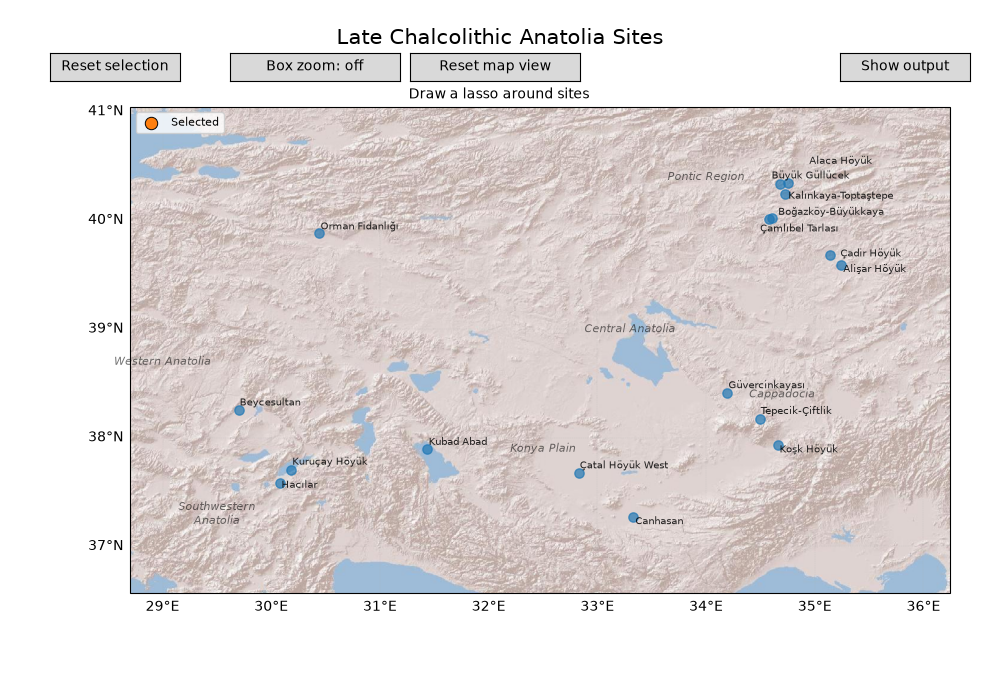

In [18]:
#%matplotlib qt
import matplotlib.pyplot as plt
import seaborn as sns
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.widgets as mwidgets
#import ipywidgets as widgets
#from IPython.display import display
from adjustText import adjust_text
from matplotlib.patches import Polygon

#comit only change
# Data already prepared in map_df
x = map_df["longitude"].to_numpy()
y = map_df["latitude"].to_numpy()
sites = map_df["site"].to_numpy()
xy = np.c_[x, y]

# Geographic projection
projection = ccrs.PlateCarree()

# Map + bar chart layout
fig = plt.figure(figsize=(10, 7))

map_position = [0.13, 0.14, 0.82, 0.72]
chart_position = [0.14, 0.18, 0.80, 0.66]

ax_map = fig.add_axes(map_position, projection=projection)
ax_corr = fig.add_axes(chart_position)
ax_corr.set_visible(False)

view_button_ax = fig.add_axes([0.84, 0.885, 0.13, 0.04])
view_button = mwidgets.Button(view_button_ax, "Show output")

chart_button_ax = fig.add_axes([0.68, 0.885, 0.13, 0.04])
chart_button = mwidgets.Button(chart_button_ax, "Chart: correlation")
chart_button_ax.set_visible(False)

reset_button_ax = fig.add_axes([0.05, 0.885, 0.13, 0.04])
reset_button = mwidgets.Button(reset_button_ax, "Reset selection")

fig.suptitle(
    "Late Chalcolithic Anatolia Sites",
    fontsize=15,
    y=0.96,
)

# ---------------------------------------------------------
# BASEMAP
# ---------------------------------------------------------

# Set map extent slightly beyond the archaeological sites
padding_lon = 1.0
padding_lat = 0.7

ax_map.set_extent(
    [
        x.min() - padding_lon,
        x.max() + padding_lon,
        y.min() - padding_lat,
        y.max() + padding_lat
    ],
    crs=projection
)

#saving base extent for later use (to reset map extent)
initial_map_extent = ax_map.get_extent(crs=projection)

#add topographic tiles
ax_map.add_image(topo_tiles, 8, zorder=0)

#allow for map to resize and adjust to the figure size
#ax_map.set_aspect("auto")


# Longitude and latitude grid
gridlines = ax_map.gridlines(
    draw_labels=True,
    linewidth=0.3,
    linestyle="--",
    alpha=0.4
)

gridlines.top_labels = False
gridlines.right_labels = False

# ---------------------------------------------------------
# APPROXIMATE ANCIENT REGION LABELS
# ---------------------------------------------------------
# Coordinates are approximate label positions, not exact boundaries.

region_labels = {
    "Central Anatolia": (33.3, 39.0),
    "Western Anatolia": (29.0, 38.7),
    "Southwestern\nAnatolia": (29.5, 37.3),
    "Cappadocia": (34.7, 38.4),
    "Konya Plain": (32.5, 37.9),
    "Pontic Region": (34.0, 40.4),
}
    #changing to save regions so they don't overlap
region_texts = []

for region, (lon, lat) in region_labels.items():
    region_text = ax_map.text(
        lon,
        lat,
        region,
        transform=projection,
        ha="center",
        va="center",
        fontsize=8,
        fontstyle="italic",
        alpha=0.55,
        zorder=1
    )
    region_texts.append(region_text)

# ---------------------------------------------------------
# ARCHAEOLOGICAL SITES
# ---------------------------------------------------------

site_sc = ax_map.scatter(
    x,
    y,
    transform=projection,
    s=45,
    alpha=0.7,
    zorder=3,
    picker=5,  # allows clicks within 5 points of a site marker
)

# Tooltip shown when the cursor is over a site
hover_annotation = ax_map.annotate(
    "",
    xy=(0, 0),
    xytext=(12, 12),
    textcoords="offset points",
    transform=projection,
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        edgecolor="black",
        alpha=0.9,
    ),
    arrowprops=dict(arrowstyle="->", color="black"),
    zorder=10,
)
hover_annotation.set_visible(False)

# Total burials at each site
burial_totals = map_df["total_burials"].to_numpy()


def on_hover(event):
    extent = ax_map.get_extent(crs=projection)
    initial_width = initial_map_extent[1] - initial_map_extent[0]
    zoom_factor = initial_width / (extent[1] - extent[0])

    if zoom_factor >= 4:
        if hover_annotation.get_visible():
            hover_annotation.set_visible(False)
            fig.canvas.draw_idle()
        return

    if event.inaxes != ax_map:
        if hover_annotation.get_visible():
            hover_annotation.set_visible(False)
            fig.canvas.draw_idle()
        return

    contains, info = site_sc.contains(event)

    if contains:
        index = info["ind"][0]

        hover_annotation.xy = (x[index], y[index])
        hover_annotation.set_text(
            f"{sites[index]}\n"
            f"Total burials: {burial_totals[index]:.0f}"
        )
        hover_annotation.set_visible(True)
        fig.canvas.draw_idle()

    elif hover_annotation.get_visible():
        hover_annotation.set_visible(False)
        fig.canvas.draw_idle()


hover_connection = fig.canvas.mpl_connect(
    "motion_notify_event",
    on_hover,
)

selected_sc = ax_map.scatter(
    [],
    [],
    transform=projection,
    s=80,
    zorder=5,
    edgecolors="black",
    linewidths=0.7,
    label="Selected"
)

#---- adjusted (non overlapping) text
site_texts = []

for site, lon, lat in zip(sites, x, y):
    label = ax_map.text(
        lon,
        lat,
        site,
        transform=projection,
        fontsize=7,
        alpha=0.85,
        zorder=4
    )
    site_texts.append(label)

adjust_text(
    site_texts,
    ax=ax_map,
    x=x,
    y=y,
    objects=region_texts,
    force_text=(0.3, 0.5),
    force_static=(0.2, 0.3),
    iter_lim=100,
)

# One detailed annotation per site. The four offsets keep the same
# 45-degree angle and distance, flipping around the site to reduce collisions.
from matplotlib.transforms import Bbox

# Candidate offsets in points, radiating farther from each site.
directions = [
    (1, 0), (-1, 0), (0, 1), (0, -1),
    (1, 1), (-1, 1), (1, -1), (-1, -1),
]
detail_offsets = sorted(
    [(dx * distance, dy * distance)
     for distance in (14, 24, 34)
     for dx, dy in directions],
    key=lambda offset: offset[0] ** 2 + offset[1] ** 2,
)

detail_labels = []
for site, lon, lat, total in zip(sites, x, y, burial_totals):
    label = ax_map.annotate(
        f"{site}\nTotal burials: {total:.0f}",
        xy=(lon, lat),
        xytext=(12, 12),
        textcoords="offset points",
        transform=projection,
        fontsize=7,
        bbox=dict(
            boxstyle="round,pad=0.25",
            facecolor="white",
            edgecolor="gray",
            alpha=0.9,
        ),
        arrowprops=dict(arrowstyle="-", color="gray", lw=0.6),
        zorder=8,
        visible=False,
        clip_on=True,
    )
    detail_labels.append(label)

label_layout_state = {"signature": None}

#when zoomed in, show detailed labels; when zoomed out, hide them. Also hide labels if the map is resized to a very small size.

def update_site_labels(event):
    extent = ax_map.get_extent(crs=projection)
    lon_min, lon_max, lat_min, lat_max = extent
    initial_width = initial_map_extent[1] - initial_map_extent[0]
    current_width = lon_max - lon_min

    if current_width <= 0:
        return

    zoom_factor = initial_width / current_width
    detailed_mode = zoom_factor >= 3

    signature = (
        round(lon_min, 6),
        round(lon_max, 6),
        round(lat_min, 6),
        round(lat_max, 6),
        round(ax_map.bbox.width, 1),
        round(ax_map.bbox.height, 1),
        detailed_mode,
    )
    if signature == label_layout_state["signature"]:
        return
    label_layout_state["signature"] = signature

    visible_indices = [
        i for i, (lon, lat) in enumerate(zip(x, y))
        if lon_min <= lon <= lon_max and lat_min <= lat <= lat_max
    ]

    for text in site_texts:
        text.set_visible(not detailed_mode)

    for label in detail_labels:
        label.set_visible(False)

    if detailed_mode:
        renderer = fig.canvas.get_renderer()
        placed_boxes = []

        # Place upper sites first, making label placement deterministic.
        visible_indices.sort(key=lambda i: y[i], reverse=True)

        renderer = fig.canvas.get_renderer()
        placed_boxes = []

        # Make exclusion boxes around all visible site markers.
        marker_radius = 7 * fig.dpi / 72
        marker_boxes = []

        for j in visible_indices:
            px, py = ax_map.transData.transform((x[j], y[j]))
            marker_boxes.append(
                Bbox.from_extents(
                    px - marker_radius,
                    py - marker_radius,
                    px + marker_radius,
                    py + marker_radius,
                )
            )

        visible_indices.sort(key=lambda i: y[i], reverse=True)

        for i in visible_indices:
            label = detail_labels[i]
            label.set_visible(True)
            best_offset = detail_offsets[0]
            best_score = (float("inf"),) * 4
            best_box = None

            for offset in detail_offsets:
                dx, dy = offset
                label.set_position(offset)
                label.set_horizontalalignment("left" if dx > 0 else "right")
                label.set_verticalalignment("bottom" if dy > 0 else "top")

                box = label.get_window_extent(renderer).expanded(1.05, 1.1)

                marker_overlaps = [
                    box.overlaps(marker_box) for marker_box in marker_boxes
                ]
                label_overlaps = [
                    box.overlaps(other) for other in placed_boxes
                ]

                score = (
                    sum(marker_overlaps),
                    sum(
                        max(0, min(box.x1, marker_box.x1)
                            - max(box.x0, marker_box.x0))
                        * max(0, min(box.y1, marker_box.y1)
                              - max(box.y0, marker_box.y0))
                        for marker_box, overlaps in zip(
                            marker_boxes, marker_overlaps
                        )
                        if overlaps
                    ),
                    sum(label_overlaps),
                    offset[0] ** 2 + offset[1] ** 2,
                )

                if score < best_score:
                    best_score = score
                    best_offset = offset
                    best_box = box

            label.set_position(best_offset)
            label.set_horizontalalignment(
                "left" if best_offset[0] > 0 else "right"
            )
            label.set_verticalalignment(
                "bottom" if best_offset[1] > 0 else "top"
            )
            placed_boxes.append(best_box)

    fig.canvas.draw_idle()


# Updates after resizing, zooming, panning, or restoring the initial extent.
fig.canvas.mpl_connect("draw_event", update_site_labels)

ax_map.set_title("Draw a lasso around sites", x=0.45, fontsize=10)
ax_map.legend(loc="upper left", fontsize=8)


# ---------------------------------------------------------
# CORRELATION HEATMAP
# ---------------------------------------------------------

corr_columns = [
    "adult_total",
    "subadult_total",
    "intramural",
    "extramural",
    "pithos_burials",
    "simple_internment",
    "refuse_pit",
    "other",
]

corr_labels = [
    "Adult",
    "Subadult",
    "Intramural",
    "Extramural",
    "Pithos",
    "Simple Interment",
    "Refuse Pit",
    "Other",
]



active_selection = {
    "indices": np.array([], dtype=int),
    "patch": None,
}

chart_mode = {"value": "correlation"}

lasso_selections = {}

#adding table to viz options
def draw_burial_table(selected):
    burial_columns = [
        "intramural",
        "extramural",
        "pithos_burials",
        "simple_internment",
        "refuse_pit",
        "other",
    ]
    burial_labels = [
        "Intramural",
        "Extramural",
        "Pithos",
        "Simple interment",
        "Refuse pit",
        "Other",
    ]

    counts = selected[burial_columns].fillna(0).sum()

    table = ax_corr.table(
        cellText=[[f"{counts[column]:,.0f}"] for column in burial_columns],
        rowLabels=burial_labels,
        colLabels=["Burial count"],
        cellLoc="center",
        loc="center",
    )
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1, 1.5)

    ax_corr.set_title(f"Burial types: {len(selected)} selected sites")
    ax_corr.axis("off")


#adding bar chart to viz options

def draw_bar_chart(selected):
    ax_corr.set_aspect("auto")

    ratio_labels = [
        "Adult/\nSubadult",
        "Intramural/\nExtramural",
        "Pithos/\nOther",
        "Simple/\nOther",
        "Refuse pit/\nOther",
    ]

    def safe_ratio(numerator, denominator):
        return numerator / denominator if denominator != 0 else np.nan

    ratio_values = [
        safe_ratio(selected["adult_total"].sum(),
                   selected["subadult_total"].sum()),
        safe_ratio(selected["intramural"].sum(),
                   selected["extramural"].sum()),
        safe_ratio(selected["pithos_burials"].sum(),
                   selected["other"].sum()),
        safe_ratio(selected["simple_internment"].sum(),
                   selected["other"].sum()),
        safe_ratio(selected["refuse_pit"].sum(),
                   selected["other"].sum()),
    ]

    bars = ax_corr.bar(ratio_labels, ratio_values)

    finite_values = np.asarray(ratio_values, dtype=float)
    finite_values = finite_values[np.isfinite(finite_values)]
    upper_limit = max(1, finite_values.max() * 1.18) if len(finite_values) else 1

    ax_corr.set_ylim(0, upper_limit)
    ax_corr.set_title("Ratios for selected sites", fontsize=10)
    ax_corr.set_ylabel("Ratio (×)")
    ax_corr.tick_params(axis="x", rotation=30)

    for bar, value in zip(bars, ratio_values):
        label = "N/A" if np.isnan(value) else f"{value:.1f}×"
        y_position = upper_limit * 0.02 if np.isnan(value) else value

        ax_corr.text(
            bar.get_x() + bar.get_width() / 2,
            y_position,
            label,
            ha="center",
            va="bottom",
            fontsize=8,
        )

## Create burial correlation heatmap function
burial_features = [
    "subadult",
    "adult",
    "intramural",
    "extramural",
    "pithoi",
    "simple_internment",
    "refuse_pit",
    "other",
]

def draw_burial_correlation(selected_sites):
    map_to_burial_site = {
        "alişar höyük": "alişar",
        "koşk höyük": "koşk",
    }

    selected_keys = (
        pd.Series(selected_sites, dtype="string")
        .str.strip()
        .str.casefold()
        .dropna()
        .map(lambda site: map_to_burial_site.get(site, site))
        .unique()
    )

    burial_site_keys = (
        burials_df["site"]
        .astype("string")
        .str.strip()
        .str.casefold()
    )

    selected_burials = burials_df.loc[
        burial_site_keys.isin(selected_keys),
        burial_features,
    ]

    if len(selected_burials) < 2:
        ax_corr.text(
            0.5,
            0.5,
            f"Need at least 2 burial records; found {len(selected_burials)}",
            transform=ax_corr.transAxes,
            ha="center",
            va="center",
        )
        return

    corr = selected_burials.corr()
    mask = np.triu(np.ones_like(corr, dtype=bool))

    sns.heatmap(
        corr,
        mask=mask,
        cmap="viridis",
        vmin=-1,
        vmax=1,
        annot=True,
        fmt=".2f",
        annot_kws={"size": 7},
        square=True,
        cbar=False,
        xticklabels=[str(label).replace("_", " ") for label in corr.columns],
        yticklabels=[str(label).replace("_", " ") for label in corr.index],
        ax=ax_corr,
    )

    ax_corr.set_title(
        f"Burial-level correlations: {len(selected_burials)} burials "
        f"from {len(selected_keys)} selected sites"
    )
    ax_corr.tick_params(axis="x", rotation=45)
    for label in ax_corr.get_xticklabels():
        label.set_horizontalalignment("right")

def show_selection(indices):
    active_selection["indices"] = indices
    ax_corr.clear()
    ax_corr.set_axis_on()

    if len(indices) == 0:
        selected_sc.set_offsets(np.empty((0, 2)))
        ax_corr.text(
            0.5, 0.5,
            "Select at least 2 sites",
            transform=ax_corr.transAxes,
            ha="center",
            va="center",
        )

    else:
        selected_sc.set_offsets(xy[indices])
        selected = map_df.iloc[indices]

        if chart_mode["value"] == "correlation":
            draw_burial_correlation(selected["site"])
        elif chart_mode["value"] == "bar":
            draw_bar_chart(selected)
        else:
            draw_burial_table(selected)
    fig.canvas.draw_idle()

#button callbacks

#reset button callback
def reset_selection(event):
    for patch in list(lasso_selections):
        patch.remove()

    lasso_selections.clear()
    active_selection["indices"] = np.array([], dtype=int)
    active_selection["patch"] = None

    show_selection(active_selection["indices"])
    fig.canvas.draw_idle()


def toggle_view(event):
    showing_map = ax_map.get_visible()

    ax_map.set_visible(not showing_map)
    ax_corr.set_visible(showing_map)
    chart_button_ax.set_visible(showing_map)
    view_button.label.set_text("Show output" if not showing_map else "Show map")

    fig.canvas.draw_idle()

#button to switch between correlation, bar chart, and table
def draw_burial_table(selected):
    burial_columns = [
        "intramural",
        "extramural",
        "pithos_burials",
        "simple_internment",
        "refuse_pit",
        "other",
    ]
    burial_labels = [
        "Intramural",
        "Extramural",
        "Pithos",
        "Simple interment",
        "Refuse pit",
        "Other",
    ]

    counts = selected[burial_columns].fillna(0).sum()

    table = ax_corr.table(
        cellText=[
            [label, f"{counts[column]:,.0f}"]
            for label, column in zip(burial_labels, burial_columns)
        ],
        colLabels=["Burial type", "Count"],
        colWidths=[0.65, 0.35],
        cellLoc="center",
        bbox=[0.08, 0.08, 0.84, 0.78],
    )
    table.auto_set_font_size(False)
    table.set_fontsize(9)

    ax_corr.set_title(f"Burial types: {len(selected)} selected sites", pad=12)
    ax_corr.axis("off")

#allows to toggle viz options
def toggle_chart(event):
    modes = ["correlation", "bar", "table"]
    current = modes.index(chart_mode["value"])
    chart_mode["value"] = modes[(current + 1) % len(modes)]
    chart_button.label.set_text(f"Chart: {chart_mode['value']}")

    if ax_corr.get_visible():
        show_selection(active_selection["indices"])


reset_button.on_clicked(reset_selection)
view_button.on_clicked(toggle_view)
chart_button.on_clicked(toggle_chart)

#creating box zoom functionality
from matplotlib.widgets import RectangleSelector

zoom_button_ax = fig.add_axes([0.23, 0.885, 0.17, 0.04])
zoom_button = mwidgets.Button(zoom_button_ax, "Box zoom: off")
zoom_button.label.set_fontsize(10)

def apply_box_zoom(click, release):
    if click.xdata is None or release.xdata is None:
        return
    if click.ydata is None or release.ydata is None:
        return

    left, right = sorted([click.xdata, release.xdata])
    bottom, top = sorted([click.ydata, release.ydata])

    if left == right or bottom == top:
        return

    ax_map.set_extent([left, right, bottom, top], crs=projection)
    fig.canvas.draw_idle()

zoom_selector = RectangleSelector(
    ax_map,
    apply_box_zoom,
    button=[1],
    useblit=False,  # changed
    interactive=False,
    props={"facecolor": "blue", "edgecolor": "black", "alpha": 0.2},
)
zoom_selector.set_active(False)

#zoom reset button callback
home_button_ax = fig.add_axes([0.41, 0.885, 0.17, 0.04])
home_button = mwidgets.Button(home_button_ax, "Reset map view")
home_button.label.set_fontsize(10)

def reset_map_view(event):
    ax_map.set_extent(initial_map_extent, crs=projection)
    fig.canvas.draw_idle()

home_button.on_clicked(reset_map_view)

def toggle_box_zoom(event):
    enabled = not zoom_selector.active
    zoom_selector.set_active(enabled)
    lasso.set_active(not enabled)
    zoom_button.label.set_text(
        "Box zoom: on" if enabled else "Box zoom: off"
    )

zoom_button.on_clicked(toggle_box_zoom)

#text realine on map resize


def change_view(change):
    if change["name"] == "value":
        show_selection(active_selection["indices"])

def on_lasso(verts):
    path = mpath.Path(verts)
    indices = np.where(path.contains_points(xy))[0]

    patch = Polygon(
        verts,
        closed=True,
        facecolor="gold",
        edgecolor="crimson",
        alpha=0.20,
        linewidth=2,
        transform=projection,
        zorder=4,
        picker=True,
    )

    ax_map.add_patch(patch)
    lasso_selections[patch] = indices

    active_selection["patch"] = patch

    show_selection(indices)

def on_pick(event):
    # Left-click a site to add it to the active selection.
    if event.artist is site_sc:
        if event.mouseevent.button != 3:
            return  # only right-clicks add/remove sites

        clicked_index = event.ind[0]
        current_indices = active_selection["indices"]

        if clicked_index in current_indices:
            updated_indices = current_indices[
                current_indices != clicked_index
            ]
        else:
            updated_indices = np.append(current_indices, clicked_index)

        updated_indices = np.unique(updated_indices).astype(int)
        active_selection["indices"] = updated_indices

        active_patch = active_selection["patch"]
        if active_patch is not None:
            lasso_selections[active_patch] = updated_indices

        show_selection(updated_indices)

    # Click a completed lasso to make it the active selection.
    elif event.artist in lasso_selections:
        active_selection["patch"] = event.artist
        show_selection(lasso_selections[event.artist])


fig.canvas.mpl_connect("pick_event", on_pick)

lasso = mwidgets.LassoSelector(
    ax_map,
    on_lasso,
    useblit=False,
    button=1,
)

plt.show()